# Notebook 04 — Evaluation, Report, Presentation and Demo Deliverables

Consumes the actual outputs of Notebook 03 and creates:
- model comparison tables and plots
- two-page PDF write-up draft
- PowerPoint presentation draft
- README and requirements files
- Streamlit demo script using the best validation-ranked **scikit-learn** model
- artifact inventory and final checklist

No metric values are invented. The notebook reports only experiments that are present in `model_metrics.csv`. Review and edit the generated write-up before submission.

## 1. Install and import dependencies

In [1]:
%pip -q install pandas numpy matplotlib seaborn reportlab python-pptx joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 6.3 MB/s eta 0:00:00


In [3]:
from pathlib import Path
import os, json, shutil, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from google.colab import drive

drive.mount('/content/drive')

DRIVE = Path('/content/drive/MyDrive')
OUTPUT_DIR = DRIVE / 'goodreads_reproduction_results'
MODEL_DIR = OUTPUT_DIR / 'models'
PLOT_DIR = OUTPUT_DIR / 'plots'
PRED_DIR = OUTPUT_DIR / 'predictions'
DELIVERABLES_DIR = OUTPUT_DIR / 'submission_deliverables'
DELIVERABLES_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = OUTPUT_DIR / 'model_metrics.csv'
if not METRICS_PATH.exists():
    raise FileNotFoundError('Run Notebook 03 first; model_metrics.csv was not found.')

metrics = pd.read_csv(METRICS_PATH)
if metrics.empty:
    raise ValueError('model_metrics.csv exists but contains no completed experiments.')

print('Rows in results:', len(metrics))
print('Columns:', metrics.columns.tolist())
display(metrics.head())

Mounted at /content/drive
Rows in results: 18
Columns: ['run_name', 'subset', 'model', 'undersampled', 'validation_roc_auc', 'epochs_trained', 'accuracy', 'sensitivity', 'specificity', 'precision', 'f1', 'roc_auc', 'threshold']


,run_name,subset,model,undersampled,validation_roc_auc,epochs_trained,accuracy,sensitivity,specificity,precision,f1,roc_auc,threshold
0,D_NeuralNetwork_undersampled,D,NeuralNetwork,True,0.745885,5.0,0.716267,0.611309,0.743553,0.382609,0.470647,0.743166,0.5
1,D_XGBoost_undersampled,D,XGBoost,True,0.741138,NaN,0.691000,0.654927,0.700378,0.362353,0.466567,0.743518,0.5
2,C_XGBoost_undersampled,C,XGBoost,True,0.741077,NaN,0.689667,0.651050,0.699706,0.360465,0.464018,0.743666,0.5
3,B_XGBoost_full,B,XGBoost,False,0.740824,NaN,0.808600,0.151535,0.979420,0.656863,0.246259,0.741629,0.5
4,B_XGBoost_undersampled,B,XGBoost,True,0.740026,NaN,0.685800,0.650404,0.695002,0.356662,0.460693,0.741634,0.5


## 2. Rank experiments using validation ROC-AUC

In [4]:
required = {'run_name', 'subset', 'model', 'validation_roc_auc', 'accuracy',
            'sensitivity', 'specificity', 'precision', 'f1', 'roc_auc'}
missing = required - set(metrics.columns)
if missing:
    raise ValueError(f'Missing columns from Notebook 03: {sorted(missing)}')

numeric_cols = [
    'validation_roc_auc', 'accuracy', 'sensitivity', 'specificity',
    'precision', 'f1', 'roc_auc', 'threshold', 'epochs_trained'
]
for col in numeric_cols:
    if col in metrics.columns:
        metrics[col] = pd.to_numeric(metrics[col], errors='coerce')

metrics['undersampled'] = metrics['undersampled'].astype(str).str.lower().isin(['true', '1'])
ranked = metrics.sort_values(['validation_roc_auc', 'f1'], ascending=False)
display(ranked[[c for c in [
    'run_name', 'subset', 'model', 'undersampled', 'validation_roc_auc',
    'accuracy', 'sensitivity', 'specificity', 'precision', 'f1', 'roc_auc',
    'threshold', 'epochs_trained'
] if c in ranked.columns]].round(4))

best_overall = ranked.iloc[0]
print('Best overall by validation ROC-AUC:', best_overall['run_name'])
print('Its test ROC-AUC (reported only after selection):', round(float(best_overall['roc_auc']), 4))

,run_name,subset,model,undersampled,validation_roc_auc,accuracy,sensitivity,specificity,precision,f1,roc_auc,threshold,epochs_trained
0,D_NeuralNetwork_undersampled,D,NeuralNetwork,True,0.7459,0.7163,0.6113,0.7436,0.3826,0.4706,0.7432,0.5,5.0
1,D_XGBoost_undersampled,D,XGBoost,True,0.7411,0.6910,0.6549,0.7004,0.3624,0.4666,0.7435,0.5,NaN
2,C_XGBoost_undersampled,C,XGBoost,True,0.7411,0.6897,0.6511,0.6997,0.3605,0.4640,0.7437,0.5,NaN
3,B_XGBoost_full,B,XGBoost,False,0.7408,0.8086,0.1515,0.9794,0.6569,0.2463,0.7416,0.5,NaN
4,B_XGBoost_undersampled,B,XGBoost,True,0.7400,0.6858,0.6504,0.6950,0.3567,0.4607,0.7416,0.5,NaN
5,C_NeuralNetwork_undersampled,C,NeuralNetwork,True,0.7370,0.6897,0.6262,0.7063,0.3566,0.4544,0.7284,0.5,5.0
6,D_LogisticRegression_undersampled,D,LogisticRegression,True,0.7171,0.7127,0.5632,0.7515,0.3708,0.4472,0.7176,0.5,NaN
7,B_LogisticRegression_undersampled,B,LogisticRegression,True,0.7163,0.7095,0.5664,0.7467,0.3677,0.4459,0.7192,0.5,NaN
8,B_NeuralNetwork_full,B,NeuralNetwork,False,0.7147,0.8035,0.2081,0.9583,0.5649,0.3041,0.7173,0.5,17.0
9,A_XGBoost_undersampled,A,XGBoost,True,0.7144,0.6675,0.6449,0.6734,0.3392,0.4446,0.7206,0.5,NaN


Best overall by validation ROC-AUC: D_NeuralNetwork_undersampled
Its test ROC-AUC (reported only after selection): 0.7432


## 3. Create comparison charts

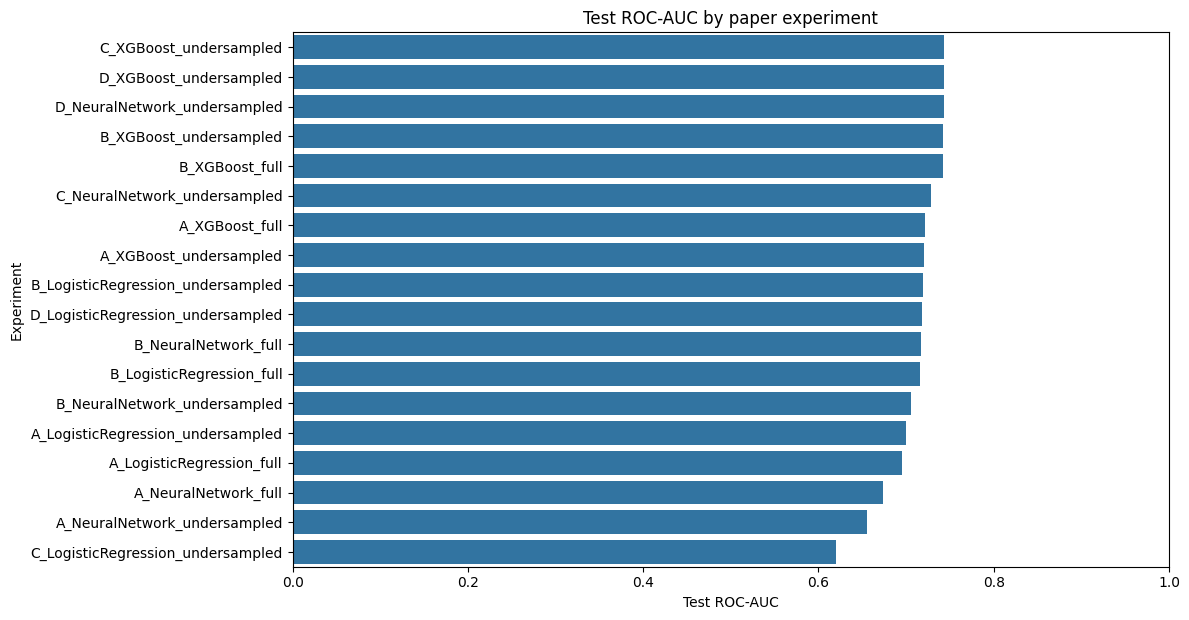

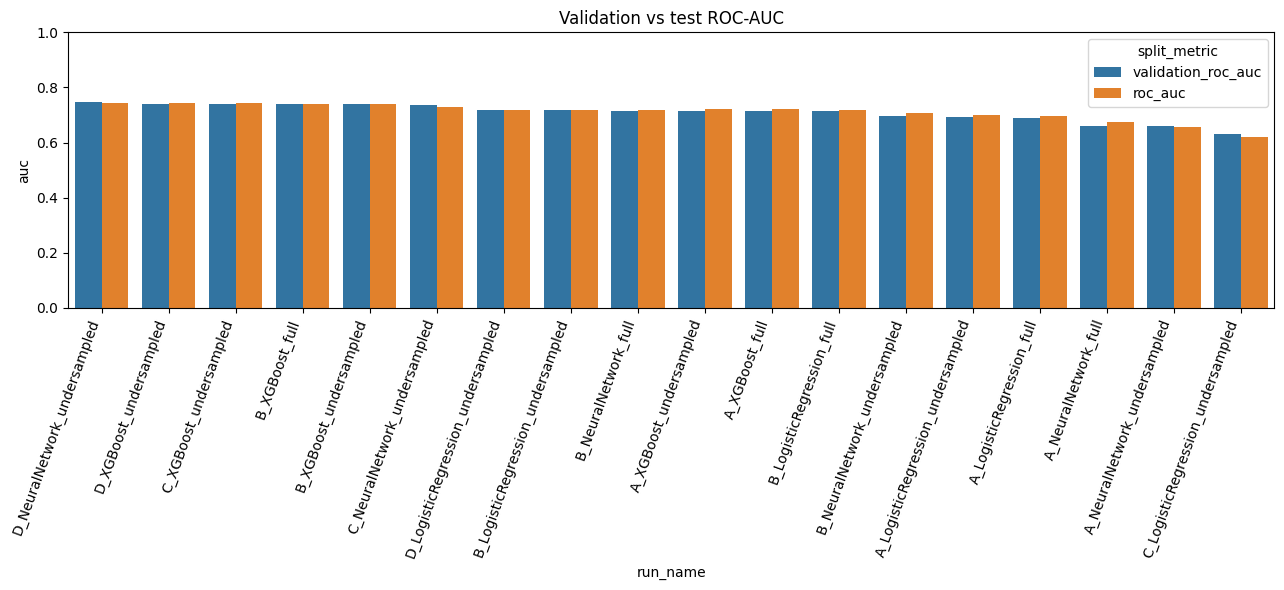

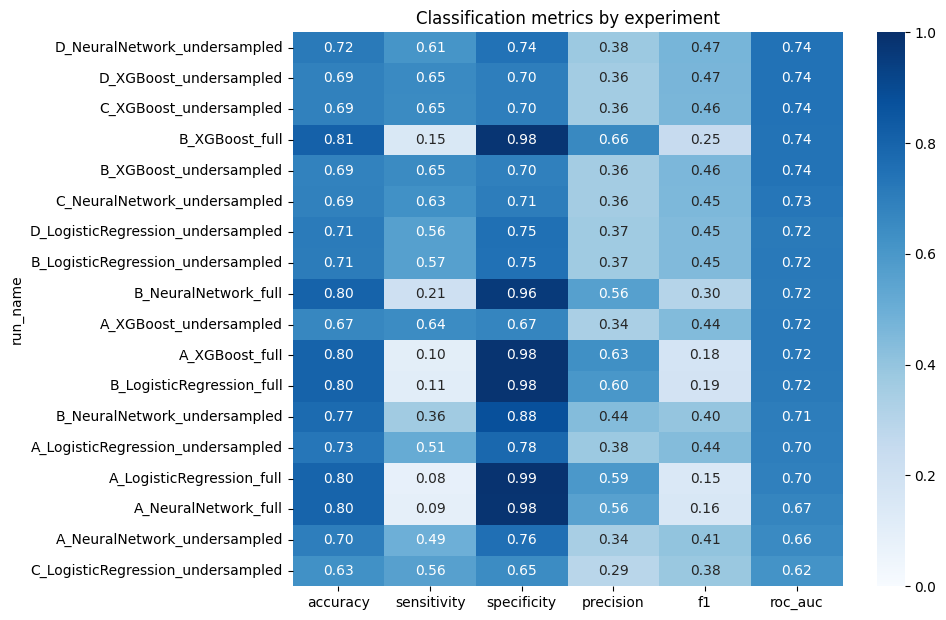

In [5]:
# Test ROC-AUC chart
chart = metrics.copy()
chart['experiment'] = chart['run_name'].astype(str)
chart = chart.sort_values('roc_auc', ascending=False)
plt.figure(figsize=(12, max(5, 0.35 * len(chart))))
sns.barplot(data=chart, x='roc_auc', y='experiment', errorbar=None)
plt.xlim(0, 1)
plt.xlabel('Test ROC-AUC'); plt.ylabel('Experiment')
plt.title('Test ROC-AUC by paper experiment')
plt.tight_layout()
plt.savefig(DELIVERABLES_DIR / 'test_auc_comparison.png', dpi=180)
plt.show()

# Validation vs test AUC
auc_long = metrics.melt(
    id_vars=['run_name', 'subset', 'model'],
    value_vars=['validation_roc_auc', 'roc_auc'],
    var_name='split_metric', value_name='auc'
)
plt.figure(figsize=(13, 6))
sns.barplot(data=auc_long, x='run_name', y='auc', hue='split_metric', errorbar=None)
plt.ylim(0, 1)
plt.xticks(rotation=70, ha='right')
plt.title('Validation vs test ROC-AUC')
plt.tight_layout()
plt.savefig(DELIVERABLES_DIR / 'validation_vs_test_auc.png', dpi=180)
plt.show()

# Metric heatmap
heat = metrics.set_index('run_name')[
    [c for c in ['accuracy', 'sensitivity', 'specificity', 'precision', 'f1', 'roc_auc']
     if c in metrics.columns]
]
plt.figure(figsize=(10, max(5, 0.35 * len(heat))))
sns.heatmap(heat, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues')
plt.title('Classification metrics by experiment')
plt.tight_layout()
plt.savefig(DELIVERABLES_DIR / 'metric_heatmap.png', dpi=180)
plt.show()

ranked.to_csv(DELIVERABLES_DIR / 'ranked_model_metrics.csv', index=False)

## 4. Best model per feature subset and artifact inventory

In [6]:
best_per_subset = (
    metrics.sort_values(['validation_roc_auc', 'f1'], ascending=False)
    .groupby('subset', as_index=False).first()
)
display(best_per_subset[['subset', 'run_name', 'model', 'undersampled',
                         'validation_roc_auc', 'roc_auc', 'accuracy',
                         'sensitivity', 'specificity', 'f1']].round(4))
best_per_subset.to_csv(DELIVERABLES_DIR / 'best_model_per_subset.csv', index=False)

# Inventory model artifacts, plots, predictions and training history files.
inventory_rows = []
for folder, kind, pattern in [
    (MODEL_DIR, 'model', '*'),
    (PLOT_DIR, 'plot', '*.png'),
    (PRED_DIR, 'prediction', '*.npz'),
    (OUTPUT_DIR, 'training_output', 'history_*.csv')
]:
    if folder.exists():
        for p in folder.glob(pattern):
            if p.is_file():
                inventory_rows.append({
                    'type': kind, 'file': str(p.relative_to(OUTPUT_DIR)),
                    'size_mb': round(p.stat().st_size / (1024**2), 3)
                })
inventory = pd.DataFrame(inventory_rows, columns=['type', 'file', 'size_mb'])
inventory.to_csv(DELIVERABLES_DIR / 'artifact_inventory.csv', index=False)
display(inventory.head(50))

,subset,run_name,model,undersampled,validation_roc_auc,roc_auc,accuracy,sensitivity,specificity,f1
0,A,A_XGBoost_undersampled,XGBoost,True,0.7144,0.7206,0.6675,0.6449,0.6734,0.4446
1,B,B_XGBoost_full,XGBoost,False,0.7408,0.7416,0.8086,0.1515,0.9794,0.2463
2,C,C_XGBoost_undersampled,XGBoost,True,0.7411,0.7437,0.6897,0.6511,0.6997,0.4640
3,D,D_NeuralNetwork_undersampled,NeuralNetwork,True,0.7459,0.7432,0.7163,0.6113,0.7436,0.4706


,type,file,size_mb
0,model,models/A_LogisticRegression_full.joblib,0.002
1,model,models/A_LogisticRegression_undersampled.joblib,0.002
2,model,models/A_XGBoost_full.joblib,0.068
3,model,models/A_XGBoost_undersampled.joblib,0.068
4,model,models/A_NeuralNetwork_full.weights.h5,0.019
5,model,models/A_NeuralNetwork_full.keras,0.020
6,model,models/A_NeuralNetwork_undersampled.weights.h5,0.019
7,model,models/A_NeuralNetwork_undersampled.keras,0.020
8,model,models/B_LogisticRegression_full.joblib,0.002
9,model,models/B_LogisticRegression_undersampled.joblib,0.002


## 5. Load run manifest and prepare report text

In [7]:
manifest_path = OUTPUT_DIR / 'training_manifest.json'
if manifest_path.exists():
    with open(manifest_path, 'r') as f:
        run_manifest = json.load(f)
else:
    run_manifest = {}

quick_run = bool(run_manifest.get('quick_run', True))
rows_used = run_manifest.get('rows_used', 'unknown')
requested = run_manifest.get('experiments_requested', 'unknown')
completed = run_manifest.get('experiments_completed', len(metrics))
failed = run_manifest.get('experiments_failed', 'unknown')

def fnum(v):
    try:
        return f'{float(v):.3f}'
    except Exception:
        return 'N/A'

best_overall = metrics.sort_values('validation_roc_auc', ascending=False).iloc[0]
best_test = metrics.sort_values('roc_auc', ascending=False).iloc[0]
top_rows = metrics.sort_values('validation_roc_auc', ascending=False).head(6)

table_md = top_rows[[
    'run_name', 'validation_roc_auc', 'accuracy', 'sensitivity',
    'specificity', 'f1', 'roc_auc'
]].round(3).to_markdown(index=False)

print('Run mode:', 'QUICK/PILOT' if quick_run else 'PAPER-SCALE SETTINGS')
print('Rows used:', rows_used)
print('Completed runs:', completed, '/', requested)
display(Markdown(table_md))

Run mode: QUICK/PILOT
Rows used: 100000
Completed runs: 18 / 18


| run_name                     |   validation_roc_auc |   accuracy |   sensitivity |   specificity |    f1 |   roc_auc |
|:-----------------------------|---------------------:|-----------:|--------------:|--------------:|------:|----------:|
| D_NeuralNetwork_undersampled |                0.746 |      0.716 |         0.611 |         0.744 | 0.471 |     0.743 |
| D_XGBoost_undersampled       |                0.741 |      0.691 |         0.655 |         0.7   | 0.467 |     0.744 |
| C_XGBoost_undersampled       |                0.741 |      0.69  |         0.651 |         0.7   | 0.464 |     0.744 |
| B_XGBoost_full               |                0.741 |      0.809 |         0.152 |         0.979 | 0.246 |     0.742 |
| B_XGBoost_undersampled       |                0.74  |      0.686 |         0.65  |         0.695 | 0.461 |     0.742 |
| C_NeuralNetwork_undersampled |                0.737 |      0.69  |         0.626 |         0.706 | 0.454 |     0.728 |

## 6. Generate the two-page PDF write-up

In [8]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
)

pdf_path = DELIVERABLES_DIR / 'goodreads_two_page_writeup.pdf'
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name='TitleCenter', parent=styles['Title'], alignment=TA_CENTER,
    fontSize=16, leading=19, spaceAfter=8
))
styles.add(ParagraphStyle(
    name='SmallBody', parent=styles['BodyText'], fontSize=8.5, leading=11, spaceAfter=5
))
styles.add(ParagraphStyle(
    name='SmallHeading', parent=styles['Heading2'], fontSize=11, leading=13, spaceBefore=6, spaceAfter=4
))

story = []
story.append(Paragraph('Text-Based Prediction of Book Review Popularity', styles['TitleCenter']))
story.append(Paragraph('Mini-project reproduction of Bridget Daly, Stanford (2021)', styles['Heading3']))
story.append(Paragraph('<b>Problem statement.</b> Predict whether a Goodreads review is popular using review metadata, engineered linguistic features, and text representations. The target is the existing binary <i>popular</i> column in the supplied filtered dataset; its threshold must be verified against the paper before claiming exact reproduction.', styles['SmallBody']))
story.append(Paragraph('Dataset and preprocessing', styles['SmallHeading']))
story.append(Paragraph(
    f'The processed dataset contains {rows_used} rows used in this training run. The input was the user-provided filtered_reviews.csv, and Notebook 02 engineered rating difference, quotation indicator, review length, average sentence/word length, POS-derived percentages, VADER sentiment, and lemmatized token text. The target was carried forward from the CSV rather than recalculated. The train/validation/test protocol was approximately 70%/15%/15%, with seed 229. Feature extraction was fitted on training data only.',
    styles['SmallBody']))
story.append(Paragraph('Methods', styles['SmallHeading']))
story.append(Paragraph(
    'Four feature subsets were evaluated: A (user reviews, days since review, user rating and rating difference); B (A plus text statistics); C (B plus Bag-of-Words); and D (B plus TF-IDF). Logistic Regression, XGBoost and a feed-forward neural network were compared. For the paper-aligned imbalance experiments, majority-class undersampling was applied to training data only. The test set was not used for model selection. Classification metrics use a 0.5 threshold; ROC-AUC is calculated from predicted probabilities.',
    styles['SmallBody']))
story.append(Paragraph('Best experiment by validation ROC-AUC', styles['SmallHeading']))
story.append(Paragraph(
    f'<b>{best_overall["run_name"]}</b>: validation ROC-AUC = {fnum(best_overall["validation_roc_auc"])}; test ROC-AUC = {fnum(best_overall["roc_auc"])}; accuracy = {fnum(best_overall["accuracy"])}; sensitivity = {fnum(best_overall["sensitivity"])}; specificity = {fnum(best_overall["specificity"])}; F1 = {fnum(best_overall["f1"])}.',
    styles['SmallBody']))
story.append(Paragraph('Top experiments', styles['SmallHeading']))

pdf_table_data = [['Experiment', 'Val AUC', 'Test AUC', 'Accuracy', 'Sens.', 'Spec.', 'F1']]
for _, r in top_rows.iterrows():
    pdf_table_data.append([
        str(r['run_name'])[:30], fnum(r['validation_roc_auc']), fnum(r['roc_auc']),
        fnum(r['accuracy']), fnum(r['sensitivity']), fnum(r['specificity']), fnum(r['f1'])
    ])
tbl = Table(pdf_table_data, repeatRows=1, colWidths=[5.1*cm, 1.5*cm, 1.5*cm, 1.5*cm, 1.3*cm, 1.3*cm, 1.1*cm])
tbl.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#d9e2f3')),
    ('TEXTCOLOR', (0,0), (-1,0), colors.black),
    ('GRID', (0,0), (-1,-1), 0.35, colors.grey),
    ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
    ('FONTSIZE', (0,0), (-1,-1), 7),
    ('VALIGN', (0,0), (-1,-1), 'MIDDLE'),
    ('LEFTPADDING', (0,0), (-1,-1), 4),
    ('RIGHTPADDING', (0,0), (-1,-1), 4),
]))
story.append(tbl)
story.append(PageBreak())

story.append(Paragraph('Results, limitations and conclusion', styles['TitleCenter']))
story.append(Paragraph('Results and interpretation', styles['SmallHeading']))
story.append(Paragraph(
    f'The highest recorded test ROC-AUC was {best_test["roc_auc"]:.3f} for {best_test["run_name"]}; this value is descriptive only because the final model should be selected using validation performance. The selected validation-ranked experiment was {best_overall["run_name"]}. Sensitivity and specificity are both reported because the target classes are imbalanced. Consult the generated comparison charts and per-subset table for detailed comparisons.',
    styles['SmallBody']))
story.append(Paragraph('Reproduction status and limitations', styles['SmallHeading']))
if quick_run:
    mode_text = 'This PDF was generated from QUICK_RUN=True and a pilot sample. It is a pipeline-validation report, not the final full-data reproduction.'
else:
    mode_text = 'The run used the paper-scale model settings configured in Notebook 03; confirm the row count and completed experiment count before submission.'
story.append(Paragraph(mode_text, styles['SmallBody']))
story.append(Paragraph(
    'Important deviations/verification points: (1) confirm that the pre-existing popular target uses the paper’s 0.02 likes-share cutoff; (2) the notebook caps TF-IDF at 10,000 terms for Colab memory safety, whereas the repository’s TF-IDF vectorizer uses min_df=0.0001 without this cap; (3) the repository groups adjective and adverb POS tags into pct_adj; (4) Logistic Regression regularization is expressed through scikit-learn C values; (5) the original paper reports results on its full filtered corpus, so pilot metrics are not directly comparable. Report software versions, runtime, hardware and any failed runs in the final submission.',
    styles['SmallBody']))
story.append(Paragraph('Conclusion', styles['SmallHeading']))
story.append(Paragraph(
    'The pipeline provides a reproducible comparison across metadata, engineered text features, BOW and TF-IDF, with Logistic Regression, gradient boosting and a neural network. The experiment table should be interpreted together with the data split, class imbalance and documented deviations. A faithful reproduction claim is appropriate only after verifying target construction and running the full dataset with the final settings.',
    styles['SmallBody']))
story.append(Paragraph('Project deliverables', styles['SmallHeading']))
story.append(Paragraph(
    'Generated with this notebook: two-page PDF write-up, PowerPoint presentation, README, requirements file, model comparison charts and a Streamlit demo script. Review the drafts, check all claims against the completed experiment logs, and commit the source code and notebooks to the required private GitHub repository.',
    styles['SmallBody']))

doc = SimpleDocTemplate(str(pdf_path), pagesize=A4, rightMargin=1.4*cm, leftMargin=1.4*cm,
                        topMargin=1.2*cm, bottomMargin=1.2*cm)
doc.build(story)
print('PDF write-up created:', pdf_path)

PDF write-up created: /content/drive/MyDrive/goodreads_reproduction_results/submission_deliverables/goodreads_two_page_writeup.pdf


## 7. Generate the PowerPoint presentation

In [9]:
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.enum.text import PP_ALIGN

ppt_path = DELIVERABLES_DIR / 'goodreads_project_presentation.pptx'
prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

def add_title_slide(title, subtitle):
    slide = prs.slides.add_slide(prs.slide_layouts[0])
    slide.shapes.title.text = title
    slide.placeholders[1].text = subtitle
    return slide

def add_bullets(title, bullets):
    slide = prs.slides.add_slide(prs.slide_layouts[1])
    slide.shapes.title.text = title
    tf = slide.placeholders[1].text_frame
    tf.clear()
    for i, bullet in enumerate(bullets):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text = str(bullet)
        p.level = 0
        p.font.size = Pt(22)
    return slide

add_title_slide(
    'Text-Based Prediction of Book Review Popularity',
    'Stanford paper reproduction | Goodreads filtered review dataset'
)
add_bullets('Problem and objective', [
    'Predict the binary popular label for a book review.',
    'Use non-text metadata, engineered NLP features, BOW and TF-IDF.',
    'Compare Logistic Regression, XGBoost and a feed-forward neural network.',
    f'Training run used {rows_used} rows; quick/pilot mode = {quick_run}.'
])
add_bullets('Paper-aligned feature subsets', [
    'A: user_reviews, days_since_review, user_rating, rating_diff',
    'B: A + review length, average lengths, POS percentages, quotation and sentiment',
    'C: B + Bag-of-Words (10,000 terms)',
    'D: B + TF-IDF',
    'Training-only undersampling for the specified experiments.'
])
add_bullets('Experimental protocol', [
    'Train / validation / test split: approximately 70% / 15% / 15%.',
    'Vectorizers are fitted on training data only.',
    'Validation ROC-AUC is used for model selection.',
    'Test metrics use a 0.5 threshold; ROC-AUC uses predicted probabilities.'
])

slide = prs.slides.add_slide(prs.slide_layouts[5])
slide.shapes.title.text = 'Current results — top validation-ranked experiments'
rows = min(7, len(top_rows) + 1)
cols = 6
table = slide.shapes.add_table(rows, cols, Inches(0.35), Inches(1.45), Inches(12.6), Inches(4.9)).table
headers = ['Experiment', 'Val AUC', 'Test AUC', 'Accuracy', 'Sensitivity', 'Specificity']
for j, h in enumerate(headers):
    table.cell(0,j).text = h
for i, (_, r) in enumerate(top_rows.head(rows-1).iterrows(), start=1):
    vals = [r['run_name'], fnum(r['validation_roc_auc']), fnum(r['roc_auc']),
            fnum(r['accuracy']), fnum(r['sensitivity']), fnum(r['specificity'])]
    for j, val in enumerate(vals):
        table.cell(i,j).text = str(val)
for row in table.rows:
    for cell in row.cells:
        for paragraph in cell.text_frame.paragraphs:
            for run in paragraph.runs:
                run.font.size = Pt(12)

add_bullets('Limitations and reproducibility', [
    'Verify that popular was constructed using the paper’s 0.02 likes-share cutoff.',
    'The notebook caps TF-IDF at 10,000 terms for Colab memory safety.',
    'QUICK_RUN/pilot results are not final full-data results.',
    'Document software versions, runtime, hardware, and deviations before submission.'
])
add_bullets('Demo and conclusion', [
    'The Streamlit demo script is generated in the deliverables folder.',
    'Enter review text and metadata to obtain a predicted popularity probability.',
    'Final model should be selected by validation results, not test results.',
    'Review the PDF, README, notebook outputs and failed-run log before submission.'
])

prs.save(ppt_path)
print('Presentation created:', ppt_path)

Presentation created: /content/drive/MyDrive/goodreads_reproduction_results/submission_deliverables/goodreads_project_presentation.pptx


## 8. Generate README, requirements and Streamlit demo script

In [10]:
readme = f'''# Goodreads Review Popularity — Stanford Paper Reproduction

This repository contains notebooks to reproduce the main feature and model experiments in Bridget Daly's *Text-Based Prediction of Book Review Popularity* (Stanford, 2021).

## Notebooks
1. `02_paper_feature_engineering.ipynb` — reads `filtered_reviews.csv` from Google Drive and builds paper-aligned linguistic features.
2. `03_paper_model_training.ipynb` — compares feature subsets A–D with Logistic Regression, XGBoost and a neural network.
3. `04_evaluation_and_deliverables.ipynb` — creates result tables, plots, a two-page PDF draft, a PowerPoint draft, README and Streamlit demo.

## Data
Place `filtered_reviews.csv` in the root of Google Drive (`MyDrive/filtered_reviews.csv`) or update `DATA_PATH` in Notebook 02. Do not commit the dataset to a public repository unless you have permission.

## Run order
Run Notebook 02 to completion, then Notebook 03, then Notebook 04. All outputs are saved to `MyDrive/goodreads_reproduction_results/`.

## Reproducibility
- Seed: 229.
- Split: approximately 70% train, 15% validation, 15% test.
- The `popular` target is inherited from the supplied CSV; verify its construction uses the paper's cutoff before claiming exact reproduction.
- Notebook 03 defaults to `QUICK_RUN=True` and `MAX_ROWS=150000` for a resource-safe pilot. Set `QUICK_RUN=False` and `MAX_ROWS=None` for the final full-data run.
- TF-IDF is capped at 10,000 terms in this Colab implementation to control memory. This is a documented deviation from the repository's uncapped TF-IDF vectorizer.
- Check `failed_experiments.csv` and `training_manifest.json` after training.

## Current run snapshot
- Rows used: {rows_used}
- Experiments completed: {completed} / {requested}
- QUICK_RUN: {quick_run}

Do not report pilot metrics as full-dataset results. Update this README after the final run.
'''
readme_path = DELIVERABLES_DIR / 'README.md'
readme_path.write_text(readme, encoding='utf-8')

requirements = '''pandas
numpy
scipy
scikit-learn
xgboost
tensorflow
nltk
tqdm
matplotlib
seaborn
joblib
streamlit
reportlab
python-pptx
'''
(DELIVERABLES_DIR / 'requirements.txt').write_text(requirements, encoding='utf-8')

# Pick the best validation-ranked scikit-learn model for a simpler demo artifact.
sk_metrics = metrics[metrics['model'].isin(['LogisticRegression', 'XGBoost'])].copy()
demo_generated = False
if not sk_metrics.empty:
    best_sk = sk_metrics.sort_values(['validation_roc_auc', 'f1'], ascending=False).iloc[0]
    source_artifact = MODEL_DIR / f"{best_sk['run_name']}.joblib"
    if source_artifact.exists():
        demo_artifact = DELIVERABLES_DIR / 'best_sklearn_demo_model.joblib'
        shutil.copy2(source_artifact, demo_artifact)
        demo_subset = str(best_sk['subset'])
        demo_generated = True
        print('Demo model:', best_sk['run_name'], '| subset:', demo_subset)
    else:
        print('No matching sklearn artifact found for best sklearn result; demo script will not be generated.')
else:
    print('No sklearn experiment present; demo script will not be generated.')

if demo_generated:
    app_source = r'''import re
import numpy as np
import pandas as pd
import streamlit as st
import joblib
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

st.set_page_config(page_title="Goodreads Review Popularity", page_icon="📚")
st.title("Goodreads Review Popularity")
st.caption("Demo for the Stanford paper reproduction. Predictions are experimental, not guarantees.")

@st.cache_resource
def load_artifact():
    return joblib.load("best_sklearn_demo_model.joblib")

@st.cache_resource
def load_nlp():
    for path, pkg in [
        ("tokenizers/punkt", "punkt"), ("tokenizers/punkt_tab", "punkt_tab"),
        ("taggers/averaged_perceptron_tagger", "averaged_perceptron_tagger"),
        ("taggers/averaged_perceptron_tagger_eng", "averaged_perceptron_tagger_eng"),
        ("corpora/stopwords", "stopwords"), ("corpora/wordnet", "wordnet"),
        ("sentiment/vader_lexicon", "vader_lexicon")
    ]:
        try:
            nltk.data.find(path)
        except LookupError:
            nltk.download(pkg, quiet=True)
    return SentimentIntensityAnalyzer(), WordNetLemmatizer(), set(stopwords.words("english"))

def features(text):
    sid, lem, stops = load_nlp()
    try:
        sentences = nltk.sent_tokenize(text) if text.strip() else []
    except LookupError:
        sentences = [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]
    try:
        raw_tokens = nltk.word_tokenize(text) if text.strip() else []
    except LookupError:
        raw_tokens = nltk.tokenize.TreebankWordTokenizer().tokenize(text)
    words = [w.lower() for w in raw_tokens if w.isalpha()]
    try:
        tags = nltk.pos_tag(words) if words else []
    except LookupError:
        tags = [(w, "NN") for w in words]
    nwords, nsent = len(words), len(sentences)
    nletters = sum(len(w) for w in words)
    pct = lambda prefixes: sum(1 for _, tag in tags if tag and tag[0] in prefixes) / nwords if nwords else 0.0
    sentiment = float(np.mean([sid.polarity_scores(s)["compound"] for s in sentences])) if sentences else 0.0
    clean = [lem.lemmatize(w) for w in words if w not in stops]
    return {
        "rating_diff": float(user_rating - avg_rating),
        "quote": int('"' in text),
        "num_words": nwords,
        "avg_sent_len": nwords / nsent if nsent else 0.0,
        "avg_word_len": nletters / nwords if nwords else 0.0,
        "pct_verbs": pct(["V"]), "pct_nouns": pct(["N"]), "pct_adj": pct(["J", "R"]),
        "sentiment": sentiment, "tokenized_words": " ".join(clean)
    }

artifact = load_artifact()
model = artifact["model"]
subset = artifact["subset"]
meta = artifact["feature_meta"]

review_text = st.text_area("Review text", "The characters were compelling and the story was enjoyable.")
c1, c2 = st.columns(2)
with c1:
    user_reviews = st.number_input("Reviews written by user", min_value=0, value=10)
    days_since_review = st.number_input("Days since review posted", min_value=0, value=30)
with c2:
    user_rating = st.slider("User rating", min_value=1.0, max_value=5.0, value=4.0, step=0.5)
    avg_rating = st.slider("Average book rating", min_value=1.0, max_value=5.0, value=3.8, step=0.1)

if st.button("Predict popularity", type="primary"):
    f = features(review_text)
    row = {
        "user_reviews": user_reviews, "days_since_review": days_since_review,
        "user_rating": user_rating, "avg_rating": avg_rating,
        **f
    }
    frame = pd.DataFrame([row])
    if meta["kind"] == "numeric":
        X = meta["imputer"].transform(frame[meta["columns"]])
    else:
        X = meta["transformer"].transform(frame[[meta["text_column"]] + meta["columns"]])
    probability = float(model.predict_proba(X)[:, 1][0])
    st.metric("Predicted probability of popular", f"{probability:.1%}")
    st.write("Predicted class:", "Popular" if probability >= artifact.get("threshold", 0.5) else "Unpopular")
    st.caption(f"Model subset: {subset}; model: {artifact['model_name']}. This demo is only as valid as the trained dataset and target definition.")
'''
    (DELIVERABLES_DIR / 'app.py').write_text(app_source, encoding='utf-8')

print('README:', readme_path)
print('requirements.txt:', DELIVERABLES_DIR / 'requirements.txt')
print('Streamlit app generated:', demo_generated)

Demo model: D_XGBoost_undersampled | subset: D
README: /content/drive/MyDrive/goodreads_reproduction_results/submission_deliverables/README.md
requirements.txt: /content/drive/MyDrive/goodreads_reproduction_results/submission_deliverables/requirements.txt
Streamlit app generated: True


## 9. Final deliverables checklist

In [11]:
checklist = {
    'metrics_csv_exists': METRICS_PATH.exists(),
    'ranked_metrics_csv': (DELIVERABLES_DIR / 'ranked_model_metrics.csv').exists(),
    'two_page_writeup_pdf': (DELIVERABLES_DIR / 'goodreads_two_page_writeup.pdf').exists(),
    'presentation_pptx': (DELIVERABLES_DIR / 'goodreads_project_presentation.pptx').exists(),
    'readme': (DELIVERABLES_DIR / 'README.md').exists(),
    'requirements': (DELIVERABLES_DIR / 'requirements.txt').exists(),
    'streamlit_demo': (DELIVERABLES_DIR / 'app.py').exists(),
    'model_artifacts_present': MODEL_DIR.exists() and any(MODEL_DIR.iterdir()),
    'training_manifest_present': (OUTPUT_DIR / 'training_manifest.json').exists()
}
display(pd.DataFrame([{'deliverable': k, 'ready': v} for k, v in checklist.items()]))
print('Notebook 04 deliverables directory:', DELIVERABLES_DIR)

,deliverable,ready
0,metrics_csv_exists,True
1,ranked_metrics_csv,True
2,two_page_writeup_pdf,True
3,presentation_pptx,True
4,readme,True
5,requirements,True
6,streamlit_demo,True
7,model_artifacts_present,True
8,training_manifest_present,True


Notebook 04 deliverables directory: /content/drive/MyDrive/goodreads_reproduction_results/submission_deliverables


## Final submission reminders
- Review the PDF and slides; replace generic statements with the final full-run settings.
- Confirm the `popular` cutoff and document the difference between the paper's original corpus and your supplied CSV.
- If `QUICK_RUN=True`, label all metrics as pilot results.
- The assignment requires a private GitHub repository shared with faculty/TAs, README setup instructions, a two-page PDF write-up, presentation, and live demo. Upload the notebooks and source code to that repository; this notebook creates drafts but cannot submit or share the repository for you.
- To run the generated demo in Colab, install Streamlit and launch it with your preferred tunneling method; alternatively run locally from the deliverables folder using `streamlit run app.py`.